#サンプルデータでの深層学習の実施

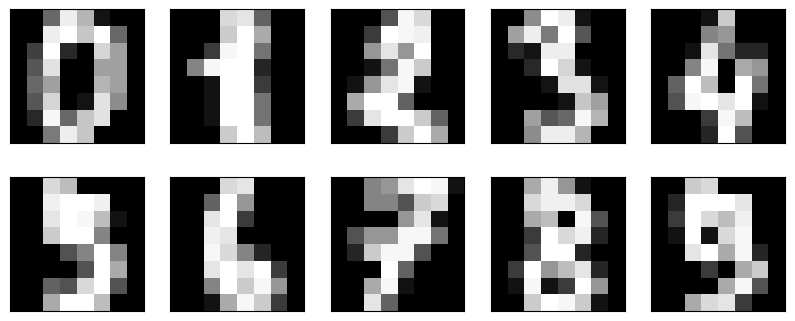

データの形状: (1797, 64)
ラベル: [0 1 2 3 4 5 6 7 8 9]


In [1]:
#学習データの例を表示

import matplotlib.pyplot as plt
from sklearn import datasets

digits_data = datasets.load_digits()

n_img = 10    #表示する画像の枚数

#画像の一部を画面に表示してみる
plt.figure(figsize=(10,4))
for i in range(n_img):
    ax = plt.subplot(2, 5, i+1)
    ax.imshow(digits_data.data[i].reshape(8, 8),cmap="Greys_r")    #scikit-learn が用意している練習用データセットを読み込む
    ax.get_xaxis().set_visible(False)    #軸を非表示にする
    ax.get_yaxis().set_visible(False)
plt.show()

print('データの形状:',digits_data.data.shape)
print('ラベル:',digits_data.target[:n_img])

In [2]:
#学習データの分割
import torch
from sklearn.model_selection import train_test_split

digit_images = digits_data.data
labels = digits_data.target
x_train, x_test, y_train, y_test = train_test_split(digit_images,labels)    #デフォルトで25％がテストデータになる。yには人間がつけた0~9のラベル（正解）が格納されている

#Tensorに変換
x_train = torch.tensor(x_train, dtype=torch.float32)    #入力：訓練用（画像データは小数の数値として扱う）（Numpyからtensorに変えておく必要がある）
y_train = torch.tensor(y_train, dtype=torch.int64)    #正解：訓練用（正解は０～９の整数）
x_test = torch.tensor(x_test, dtype=torch.float32)    #入力：テスト用
y_test = torch.tensor(y_test, dtype=torch.int64)    #正解：テスト用

In [3]:
#モデルの設計
from torch import nn    #PyTorch でニューラルネットワークを作るための部品(層や活性化関数など)がまとまったモジュール

net = nn.Sequential(     #今回は試しに　入力層 → 隠れ層×２ → 出力層　のモデルを作成する。全結合層が64→32→16と推移する。出力は0~9の10種類。
    nn.Linear(64,32),    #層への入力数=64(8×8ピクセル)、層のニューロン数＝32    #全結合層(すべての入力がすべてのニューロンにつながる層)
    nn.ReLU(),    #活性化関数（ReLU関数）
    nn.Linear(32,16),    #一層目の出力数＝二層目の入力数
    nn.ReLU(),
    nn.Linear(16,10)
)
print(net)

Sequential(
  (0): Linear(in_features=64, out_features=32, bias=True)
  (1): ReLU()
  (2): Linear(in_features=32, out_features=16, bias=True)
  (3): ReLU()
  (4): Linear(in_features=16, out_features=10, bias=True)
)


In [4]:
#設計したモデルで実際に学習開始
from torch import optim    #パラメータを更新する方法(最適化手法)がまとまったモジュール

#損失関数の定義
loss_fnc = nn.CrossEntropyLoss()    #ソフトマックス関数＋交差エントロピー誤差関数

#最適化手法の定義
optimizer = optim.SGD(net.parameters(), lr=0.01)    #SGDモデルのパラメータを渡す　#学習率=0.01

#損失のログ（学習中の誤差を毎回ためておく空のリスト。あとでグラフにして、学習の進み方を確認する）
record_loss_train = []
record_loss_test = []


#学習開始
for i in range(1000):    #訓練データを1000回使う。１回のループで訓練データを一周する。
    #パラメータの勾配を０に（PyTorch は勾配を「上書き」ではなく「足し算」で保存する仕様なので、リセットする必要がある）
    optimizer.zero_grad()

    #順伝播（訓練データとテストデータをモデルに通して、予測(10クラス分のスコア)を出す）
    y_pred_train = net(x_train)
    y_pred_test = net(x_test)    #テストデータは学習には用いない。ループ中での途中経過を観察するため（学習の進展⇔過学習 の経過をチェックするため）に毎度誤差を求めている。

    #予測と正解を比べて、誤差を求め、記録する
    loss_train = loss_fnc(y_pred_train, y_train)
    loss_test = loss_fnc(y_pred_test, y_test)
    record_loss_train.append(loss_train.item())
    record_loss_test.append(loss_test.item())

    #逆伝播（各パラメータを動かすと誤差がどう変わるか(勾配)を計算する）    #テスト用の誤差は記録するだけ
    loss_train.backward()

    #逆伝播で計算した勾配をもとに、誤差が減る方向へパラメータを実際に更新
    optimizer.step()

    if i%100 == 0:    #100回ごとにモデルの精度の経過を表示
        print("Epoch:", i, "Loss_Train:", loss_train.item(), "Loss_Test:", loss_test.item())


Epoch: 0 Loss_Train: 2.520599603652954 Loss_Test: 2.4598896503448486
Epoch: 100 Loss_Train: 0.9364431500434875 Loss_Test: 0.9736794829368591
Epoch: 200 Loss_Train: 0.32705429196357727 Loss_Test: 0.40780889987945557
Epoch: 300 Loss_Train: 0.1999199539422989 Loss_Test: 0.29545608162879944
Epoch: 400 Loss_Train: 0.1472025066614151 Loss_Test: 0.2525577247142792
Epoch: 500 Loss_Train: 0.11702818423509598 Loss_Test: 0.22909659147262573
Epoch: 600 Loss_Train: 0.09691527485847473 Loss_Test: 0.2145918905735016
Epoch: 700 Loss_Train: 0.08218127489089966 Loss_Test: 0.20452344417572021
Epoch: 800 Loss_Train: 0.07065560668706894 Loss_Test: 0.19696928560733795
Epoch: 900 Loss_Train: 0.06135866791009903 Loss_Test: 0.1907411515712738


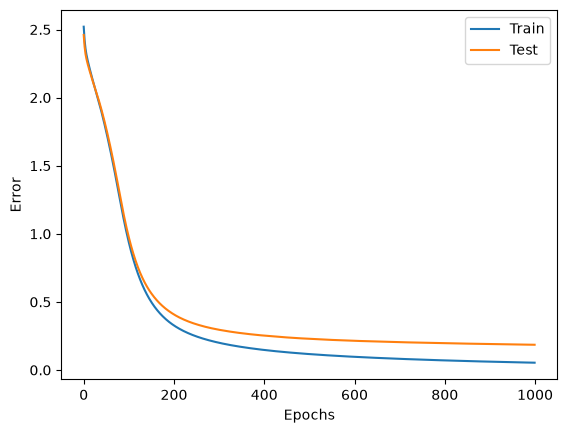

In [5]:
#誤差の推移の確認（record_loss_に保存しておいたデータを使う）
plt.plot(range(len(record_loss_train)), record_loss_train, label="Train")
plt.plot(range(len(record_loss_test)), record_loss_test, label="Test")
plt.legend()

plt.xlabel("Epochs")
plt.ylabel("Error")
plt.show()

In [6]:
#正解率の計算
y_pred_test = net(x_test)
count = (y_pred_test.argmax(1) == y_test).sum().item()
print("正解率:", str(count/len(y_pred_test)*100) + "%")
#train_test_split のランダム分割と、重みの初期値のランダム性により、教科書とは微妙に異なる正解率になる

正解率: 94.22222222222221%


＃訓練済みのモデルを用いた予測

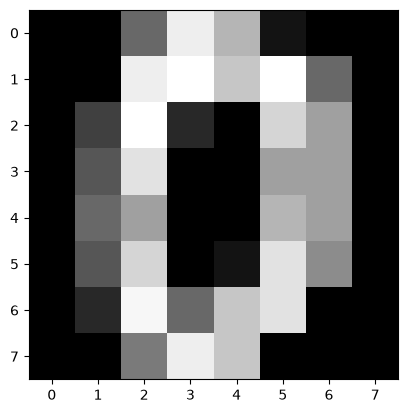

正解： 0 予測結果： 0


In [7]:
#予測したい画像の用意
img_id = 0
x_pred = digit_images[img_id]
image = x_pred.reshape(8, 8)
plt.imshow(image, cmap="Greys_r")
plt.show()

x_pred = torch.tensor(x_pred, dtype=torch.float32)
y_pred = net(x_pred)
print("正解：", labels[img_id], "予測結果：", y_pred.argmax().item())